# Agentic AI for Science, Part 1b: Benchmarking the Agent, and How Far to Trust It

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nathanmaulding/tutorial-projects/blob/main/agentic-ai-for-science/02_benchmarking_and_reliability.ipynb)

Notebook 01 built a mechanism-discovery agent and watched it work. One good-looking run proves nothing, though. Before anyone uses an agent's conclusions in research, we need to know **how often it's right, where it fails, whether its parts actually help, and whether its self-reported confidence means anything.**

**What you'll learn**

1. How to design a benchmark for a scientific agent: ground truth, held-out tests, difficulty tiers
2. **Baselines and ablations**: is the agent better than a simple non-AI method, and which components earn their place?
3. Reading results honestly: confidence intervals on small samples
4. **Failure analysis**: *how* the agent goes wrong matters as much as how often
5. **Reliability**: run-to-run consistency and calibration of stated confidence
6. Cost per correct answer, and small model vs frontier model

**Runtime:** seconds. Everything here reads recorded results; no API key needed.

> 🎬 *Video walkthrough: coming soon.*

## 0. Setup

In [1]:
import os, sys, json
if "google.colab" in sys.modules and not os.path.exists("agentlab"):
    !git clone -q --depth 1 https://github.com/nathanmaulding/tutorial-projects.git
    %cd tutorial-projects/agentic-ai-for-science
    !pip install -q -r requirements.txt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mechanism_discovery import analysis as A

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 11})
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
pd.set_option("display.precision", 3)
df = A.load()
print(f"{len(df)} recorded runs, total API spend ${df.usd.fillna(0).sum():.2f}")

306 recorded runs, total API spend $4.01


## 1. The benchmark

**18 tasks, each simulated from a known mechanism**, with realistic noise. Each run is scored on two questions, and both must be *yes*:

1. **Mechanism:** did it identify the right one?
2. **Prediction:** does its fitted model predict **hidden held-out conditions** (a higher dose, a higher inhibitor level) within 2x the error of the *true* model refit to the same noisy data? (The threshold is clipped to between 5% and 15% relative error.)

Tasks come in two tiers:

| Tier | Tasks | What it tests |
|---|---|---|
| **standard** (12) | six enzyme mechanisms, three pharmacokinetic (PK) models, three drug-effect (PD) models | the textbook skill: pick the right model from a known set |
| **hard** (6) | **out-of-library** ×3: mechanisms deliberately absent from the agent's library | can it notice nothing fits and build a new model? |
| | **null** ×1: the drug has no effect | does it resist finding a pattern in noise (a false discovery)? |
| | **identifiability** ×1: data that can't determine Km | does it report what the data *can't* tell you? |
| | **nonlinear PK** ×1: saturable elimination | does it notice dose-dependent behaviour? |

Each task was run on **2 independent noise seeds**. The Haiku methods ran **twice per seed** to measure consistency; the more expensive Opus agent ran once per seed, and the Opus single call once on seed 0 only, so its sample is smaller.

In [2]:
from mechanism_discovery.tasks import TASKS
pd.DataFrame([{"task": t.id, "tier": t.tier, "domain": t.domain, "true mechanism": t.truth,
               "agent will be asked to": t.use} for t in TASKS])

,task,tier,domain,true mechanism,agent will be asked to
0,enz_mm,standard,enzyme,mm,predict rates at substrate levels outside the ...
1,enz_hill,standard,enzyme,hill,predict rates at substrate levels outside the ...
2,enz_substrate_inhibition,standard,enzyme,substrate_inhibition,predict rates at higher substrate levels
3,enz_competitive,standard,enzyme,competitive_inhibition,predict rates at higher inhibitor concentrations
4,enz_uncompetitive,standard,enzyme,uncompetitive_inhibition,predict rates at higher inhibitor concentrations
5,enz_noncompetitive,standard,enzyme,noncompetitive_inhibition,predict rates at higher inhibitor concentrations
6,pk_1cmt_iv,standard,pk,pk_1cmt_iv,predict concentrations after a 500 mg dose
7,pk_2cmt_iv,standard,pk,pk_2cmt_iv,predict concentrations after a 500 mg dose
8,pk_1cmt_oral,standard,pk,pk_1cmt_oral,predict concentrations after a 500 mg dose
9,pd_direct_emax,standard,pd,pd_direct_emax,predict the biomarker time course at 60 mg and...


**The methods compared** (an *ablation* removes one component to see what it was contributing):

| Method | What it gets |
|---|---|
| **Exhaustive search** | no AI: fit *every* library model for the domain, pick the lowest BIC |
| **Single LLM call** | the model reads the data table and answers once, with no tools (parameters by eye) |
| **Agent, no retrieval** | the full loop with analysis and fitting tools, but no mechanism library: it must write every model itself |
| **Agent, full** | everything from notebook 01 |

Exhaustive search is the baseline to beat, and it's a strong one: on the standard tier it's essentially perfect by construction, and it costs nothing. An agent has to justify itself on the problems a fixed search *can't* solve.

## 2. Headline results

In [3]:
s = A.summary(df)
s.style.format({c: "{:.0%}" for c in ["success", "standard tier", "hard tier", "out-of-library"]}
               | {"median held-out error": "{:.3f}", "cost per run ($)": "${:.4f}", "total cost ($)": "${:.3f}",
                  "mean steps": "{:.1f}"}, na_rep="-")

,runs,success,standard tier,hard tier,out-of-library,median held-out error,cost per run ($),total cost ($),mean steps
method,,,,,,,,,
exhaustive,36,81%,96%,50%,0%,0.029,$0.0000,$0.000,0.0
single_shot · haiku-5-5,72,40%,44%,33%,0%,0.075,$0.0009,$0.062,1.0
single_shot · opus-5-5,18,83%,92%,67%,67%,0.017,$0.0243,$0.438,1.0
agent_no_retrieval · haiku-5-5,72,90%,96%,79%,75%,0.024,$0.0031,$0.225,5.7
agent_full · haiku-5-5,72,97%,100%,92%,92%,0.024,$0.0027,$0.193,5.7
agent_full · opus-5-5,36,100%,100%,100%,100%,0.024,$0.0859,$3.093,6.3


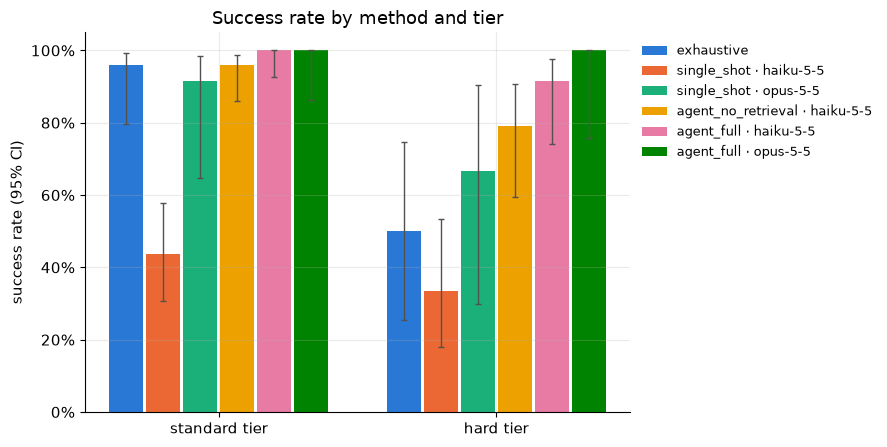

In [4]:
methods = list(s.index)
tiers = ["standard", "hard"]
fig, ax = plt.subplots(figsize=(9, 4.6))
w = 0.8 / len(methods)
for i, m in enumerate(methods):
    for j, tier in enumerate(tiers):
        d = df[(df.method == m) & (df.tier == tier)]
        p, n = d.success.mean(), len(d)
        lo, hi = A.wilson(p, n)
        x = j + (i - (len(methods) - 1) / 2) * w
        ax.bar(x, p, w * 0.92, color=SERIES[i % len(SERIES)], label=m if j == 0 else None)
        ax.errorbar(x, p, yerr=[[max(p - lo, 0)], [max(hi - p, 0)]], color="#52514e", lw=1, capsize=2)
ax.set_xticks(range(len(tiers)), [f"{t} tier" for t in tiers])
ax.set_ylim(0, 1.05); ax.set_ylabel("success rate (95% CI)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(1, 1))
ax.set_title("Success rate by method and tier")
plt.tight_layout(); plt.show()

### What we found

- **Tools beat size.** The full agent on the *small* model (Claude Haiku 5.5) solved **97%** of runs for **$0.003** each. The *frontier* model (Claude Opus 5.5) answering in one call, without tools, solved 83% at 8x the cost. The same small model without tools managed only 40%: it usually named a sensible mechanism, but parameters guessed by eye don't predict new experiments. Most of the gap is the **fitting and diagnostic tools**, not model knowledge.
- **The full Opus agent solved all 36 runs**, including every out-of-library mechanism, at $0.086 per run.
- **Exhaustive search is excellent until the library runs out.** It's near-perfect on the standard tier and costs nothing, but it scores **0% on out-of-library mechanisms**, because it can only choose among the models it was given. That's exactly where agents earn their cost.
- **Retrieval helps most when it matters most.** Removing the mechanism library (the no-retrieval ablation) dropped the Haiku agent from 97% to 90% overall and from 92% to 75% on out-of-library tasks. That's because the library's cards include warnings about *when the standard models stop applying*.
- **No false discoveries.** Every method correctly concluded "no drug effect" on the null task, and every agent flagged or avoided the unidentifiable parameter.

**Why the error bars matter.** With a few dozen runs per cell, a success rate of 80% could plausibly be anywhere from about 60% to 90%. The bars are 95% Wilson intervals, a standard interval for proportions that behaves well at small sample sizes and near 0% or 100%. **Two methods whose intervals overlap heavily have not been shown to differ.** Agent papers that report a single run per task, with no intervals, often can't support the comparisons they make.

## 3. Task by task

In [5]:
t = A.by_task(df)
t.style.format("{:.0%}", na_rep="-").background_gradient(cmap="Blues", vmin=0, vmax=1)

> ⏸️ **Pause and predict:** before reading on, find the rows where exhaustive search scores 0%. What do they have in common, and which method does best there?

## 4. How methods fail

A success rate hides *how* things go wrong. Different failures have very different consequences in research:

- **wrong mechanism**: picked the wrong model from the library
- **forced a library model onto a new mechanism**: the most dangerous everyday failure. The answer looks well-fitted and confident, but it extrapolates badly.
- **false discovery**: claimed a drug effect in pure noise
- **over-claimed unidentifiable parameters**: reported numbers the data can't determine
- **right mechanism, poor prediction**: a fitting problem, not a reasoning one
- **no result**: ran out of steps or budget, or produced unusable output

In [6]:
A.failures(df)

method,agent_full · haiku-5-5,agent_full · opus-5-5,agent_no_retrieval · haiku-5-5,exhaustive,single_shot · haiku-5-5,single_shot · opus-5-5
failure,,,,,,
forced a library model onto a new mechanism,1,0,1,6,9,1
"right mechanism, poor prediction",1,0,5,0,33,2
success,70,36,65,29,29,15
wrong mechanism,0,0,1,1,1,0


## 5. Reliability: would it give the same answer twice?

An agent is a stochastic process: the same model on the same data can take a different path. If two runs on identical inputs disagree, neither can be fully trusted alone. We ran every LLM method twice on every task and seed.

In [7]:
A.consistency(df).style.format({"same verdict across repeats": "{:.0%}", "same mechanism across repeats": "{:.0%}"})

,same verdict across repeats,same mechanism across repeats,task-seed pairs run twice
method,,,
agent_full · haiku-5-5,94%,94%,36
agent_no_retrieval · haiku-5-5,86%,81%,36
single_shot · haiku-5-5,69%,92%,36


### Calibration: does "90% confident" mean 90%?

At submission the agent states its probability that the mechanism is right. A **calibrated** agent is right about as often as it claims. The **Brier score** is the mean squared gap between stated confidence and outcome (0 is perfect; always saying 50% scores 0.25).

In [8]:
display(A.calibration(df))
A.brier(df).rename("Brier score (lower is better)").to_frame()

runs  stated  actual
method                         bin                              
agent_full · haiku-5-5         [0.6, 0.8)     29   0.660   0.931
                               [0.8, 0.9)     40   0.831   1.000
                               [0.9, 1.01)     3   0.900   1.000
agent_full · opus-5-5          [0.6, 0.8)      6   0.692   1.000
                               [0.8, 0.9)     23   0.848   1.000
                               [0.9, 1.01)     7   0.909   1.000
agent_no_retrieval · haiku-5-5 [0.0, 0.6)      5   0.520   0.600
                               [0.6, 0.8)     29   0.678   0.862
                               [0.8, 0.9)     38   0.821   0.974

,Brier score (lower is better)
method,
agent_full · haiku-5-5,0.070
agent_full · opus-5-5,0.033
agent_no_retrieval · haiku-5-5,0.104


**Reading the calibration table:** the agents are **under-confident**. When the Haiku agent says it's 60-80% sure, it's right about 93% of the time. In science that's the safer direction to be wrong in, but it means stated confidence can't yet be used as a filter. A calibrated agent would let us auto-accept its high-confidence answers. On these tasks, a better reliability signal is whether the agent's own residual diagnostics came back clean.

**Consistency:** repeated full-agent runs on identical data reached the same verdict 94% of the time. The disagreements are concentrated in the hard tier. When two runs disagree, that's itself a useful flag that a problem needs a human.

## 6. Small model vs frontier model, and cost

In [9]:
c = s[["success", "hard tier", "cost per run ($)"]].copy()
c["cost per success ($)"] = s["total cost ($)"] / (s["success"] * s["runs"]).replace(0, np.nan)
c.style.format({"success": "{:.0%}", "hard tier": "{:.0%}", "cost per run ($)": "${:.4f}",
                "cost per success ($)": "${:.4f}"}, na_rep="-")

,success,hard tier,cost per run ($),cost per success ($)
method,,,,
exhaustive,81%,50%,$0.0000,$0.0000
single_shot · haiku-5-5,40%,33%,$0.0009,$0.0021
single_shot · opus-5-5,83%,67%,$0.0243,$0.0292
agent_no_retrieval · haiku-5-5,90%,79%,$0.0031,$0.0035
agent_full · haiku-5-5,97%,92%,$0.0027,$0.0028
agent_full · opus-5-5,100%,100%,$0.0859,$0.0859


## 7. What this benchmark does and doesn't show

**It shows** how the agent performs on well-posed, simulated mechanism-discovery problems with known answers, relative to clear baselines, with failure modes and reliability measured rather than assumed.

**Limits, stated plainly:**
- **Simulated data.** Real experiments have outliers, batch effects, missing values and mechanisms more tangled than any of these 18. Simulation is what makes ground truth possible; it's the right first test, not the last.
- **Small benchmark.** 18 tasks × 2 seeds. The confidence intervals are wide, deliberately shown, and should be read before any comparison.
- **The library is ours.** Results depend on the cards and tool descriptions we wrote. A different library could help or hurt.
- **Out-of-library is still textbook.** The three "novel" mechanisms are absent from the library but well known in the literature, so a model may recall them. A truly new mechanism is a harder test. Part 2 goes there with real data.

## Try it yourself

1. Filter `df` to a single task and compare the agents' `summary` fields: do failed runs sound less sure?
2. Plot held-out error against stated confidence for the full agent.
3. Run the benchmark on one more model (`python -m mechanism_discovery.run --arms agent_full --model claude-sonnet-5-5`) and re-run this notebook.